# **Homework 03 - Machine Learning - Zoomcamp 2026**

## **Imports**

In [85]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split


## **Download lead scoring dataset**

In [38]:
DATA_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df_leads = pd.read_csv(DATA_URL)

df_leads.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## **EDA and data preparation**

- **Check missing values**

In [39]:
df_leads.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

- **Imputation of missing values**

In [40]:
df_leads.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


There are missing values in both categorical and numerical features. To handle them, we first separate the columns by type.

The data types in the DataFrame are `str`, `int64` and `float64`. The `str` columns are the categorical features, while the `int64` and `float64` ones are the numerical features. The target `converted` is also stored as `int64`, so we leave it out of the list of numerical features.

In [41]:
target = "converted"

cat_cols = list(df_leads.dtypes[df_leads.dtypes == "str"].index)
num_cols = list(df_leads.dtypes[df_leads.dtypes != "str"].index)

print(f"Categorical features: {cat_cols}")
print(f"Numerical features: {num_cols}")

Categorical features: ['lead_source', 'industry', 'employment_status', 'location']
Numerical features: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score', 'converted']


Now we replace the missing values with `'NA'` for the categorical features and with `0.0` for the numerical ones:

In [42]:
df_leads[cat_cols] = df_leads[cat_cols].fillna("NA")
df_leads[num_cols] = df_leads[num_cols].fillna(0.0)

df_leads.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

- **Target variable distribution**

<Axes: xlabel='converted', ylabel='count'>

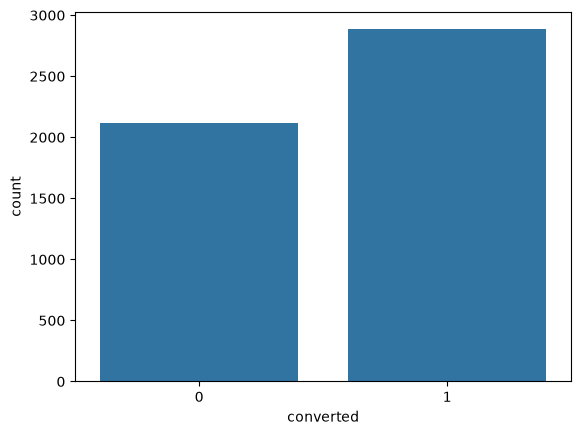

In [44]:
sns.countplot(x=df_leads[target])

## **Question 01**

- **Problem statement: What is the most frequent observation (mode) for the column `industry`?**

### **Solution**

In [47]:
df_leads["industry"].value_counts()

industry
technology       1173
retail            925
healthcare        840
finance           720
education         639
manufacturing     463
NA                240
Name: count, dtype: int64

> **Answer: The mode of the `industry` column is `technology`. Note that `NA`, the value we used to fill the missing entries, is the least frequent one.**

## **Question 02**

- **Problem statement: Create the correlation matrix for the numerical features of your dataset. What are the two features that have the biggest correlation?**

### **Solution**

The correlation is a metric to measure the dependence between two **numerical** variables, so we compute the correlation matrix looking only at the numerical features of our dataset.

In [49]:
df_corr = df_leads[num_cols].corr()

df_corr

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,1.000000,0.161300,0.122842,0.229496,0.189652
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204,0.395038
interaction_count,0.122842,0.721609,1.000000,0.915746,0.448624
lead_score,0.229496,0.757204,0.915746,1.000000,0.483246
converted,0.189652,0.395038,0.448624,0.483246,1.000000


For visualization purposes, we plot the correlation matrix using the heatmap method from the **Seaborn Library**:

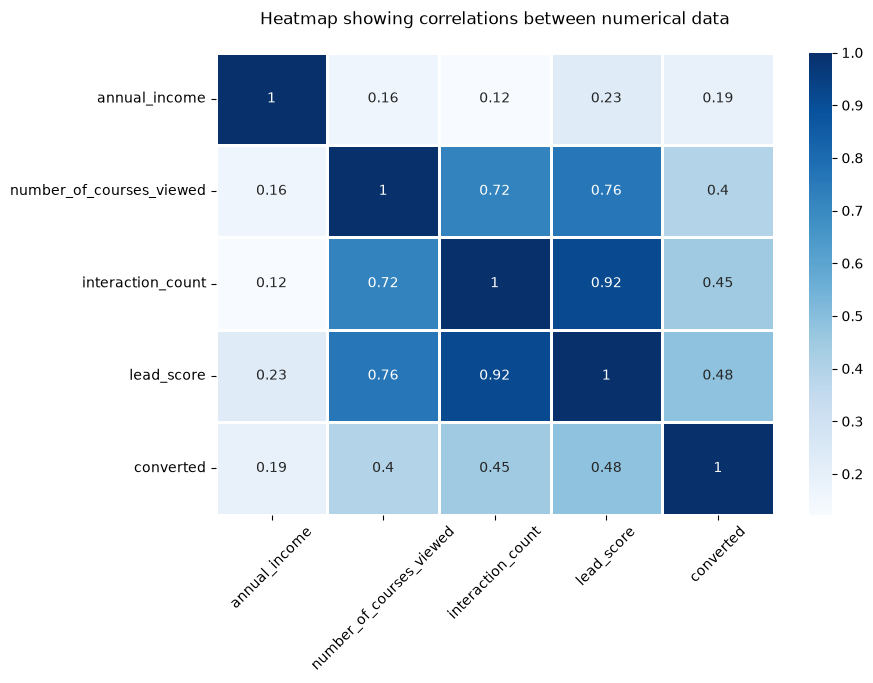

In [62]:
fig, ax = plt.subplots(figsize=(9,6))
sns.heatmap(df_corr, annot=True, linewidths=1.0,cmap="Blues")
ax.tick_params(axis="x", labelrotation=45)
ax.set(title="Heatmap showing correlations between numerical data\n")
plt.show()

We can use the `.unstack()` method to reshape the correlation matrix into a Series indexed by pairs of features, which makes it easy to sort the pairs by correlation. Since the matrix is symmetric, each pair appears twice, and the diagonal carries no information, so we keep only the upper triangle:

In [73]:
# Keep only the upper triangle of the matrix, without the diagonal
upper_triangle = np.triu(np.ones(df_corr.shape, dtype=bool), k=1)

df_corr_upper = df_corr.where(upper_triangle)

df_corr_upper

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
annual_income,NaN,0.1613,0.122842,0.229496,0.189652
number_of_courses_viewed,NaN,NaN,0.721609,0.757204,0.395038
interaction_count,NaN,NaN,NaN,0.915746,0.448624
lead_score,NaN,NaN,NaN,NaN,0.483246
converted,NaN,NaN,NaN,NaN,NaN


The 2d matrix becomes a list of pairs `(original column, row indexes) -> value` (actually a `Pandas.Series`!):

In [ ]:
df_corr_upper.unstack()

annual_income             annual_income                    NaN
                          number_of_courses_viewed         NaN
                          interaction_count                NaN
                          lead_score                       NaN
                          converted                        NaN
number_of_courses_viewed  annual_income               0.161300
                          number_of_courses_viewed         NaN
                          interaction_count                NaN
                          lead_score                       NaN
                          converted                        NaN
interaction_count         annual_income               0.122842
                          number_of_courses_viewed    0.721609
                          interaction_count                NaN
                          lead_score                       NaN
                          converted                        NaN
lead_score                annual_income               0

In [83]:
df_corr_upper.unstack().dropna().sort_values(ascending=False)

lead_score                interaction_count           0.915746
                          number_of_courses_viewed    0.757204
interaction_count         number_of_courses_viewed    0.721609
converted                 lead_score                  0.483246
                          interaction_count           0.448624
                          number_of_courses_viewed    0.395038
lead_score                annual_income               0.229496
converted                 annual_income               0.189652
number_of_courses_viewed  annual_income               0.161300
interaction_count         annual_income               0.122842
dtype: float64

> **Answer: The two features with the biggest correlation are `interaction_count` and `lead_score`.**

## **Split the dataset**

Here we apply the following split:

- **60% train**

- **20% validation**

- **20% test**

We first allocate 80% of the dataset for training and validation, while the remaining 20% is reserved for testing:

In [ ]:
df_full_train, df_test = train_test_split(df_leads, test_size=0.20, random_state=42)

Now, we need to further split the full training set so that the validation set represents 20% of the entire dataset, and the training set accounts for 60%. In other words, we just need to allocate 25% of the full training set for validation, by the following logic:

- **How much percent of the full training set represents 20% of the whole dataset?**

\begin{equation}
\frac{20\%}{80\%} = 25\%
\end{equation}

In [90]:
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

len(df_train) +  len(df_val) +  len(df_test) == len(df_leads)

True

In [93]:
df_train.reset_index(drop=True)

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,paid_ads,finance,employed,asia,65980.0,2,3,0.37,1
1,events,finance,employed,south_america,71662.0,0,0,0.09,0
2,referral,NA,employed,asia,40220.0,2,5,0.55,1
3,organic_search,finance,employed,north_america,88352.0,2,2,0.45,0
4,events,technology,employed,north_america,89316.0,1,5,0.00,1
...,...,...,...,...,...,...,...,...,...
2995,paid_ads,finance,employed,asia,81522.0,1,3,0.29,0
2996,social_media,retail,employed,asia,33075.0,1,1,0.30,1
2997,organic_search,finance,employed,africa,71532.0,3,5,0.58,1
2998,social_media,retail,employed,asia,48836.0,0,0,0.03,0
